# Penguin Species Classification

**Stack:** Python, pandas, seaborn, scikit-learn

> **Project origin.** Originally completed as a weekly assignment in an Introduction to Machine Learning course (KBTU). This version is restructured as a standalone case study and extended with the additional analysis listed below.

**What this version adds**

- missing-value handling moved **inside the modelling pipeline** to avoid data leakage
- baseline model plus KNN, logistic regression and random forest
- 5-fold stratified cross-validation (a single 69-row test set is too small to trust)
- confusion matrix, classification report and permutation feature importance

## Goal

Predict a penguin's species (Adelie, Chinstrap, Gentoo) from body measurements, island and sex, and understand which
features matter.

**Data:** the `penguins` dataset (344 birds): `species`, `island`, `bill_length_mm`, `bill_depth_mm`,
`flipper_length_mm`, `body_mass_g`, `sex`.

In [70]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 1. Data overview and cleaning

In [72]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").T)
df.isna().sum().to_frame("missing values").T

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
dtype,object,object,float64,float64,float64,float64,object


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
missing values,0,0,2,2,2,2,11


Two rows have no measurements at all, so they carry no information and are dropped.
The remaining missing values (mostly `sex`) are **not** filled here: they are imputed inside the modelling pipeline,
using statistics learned from the training data only. Filling them on the full dataset before splitting would leak
information from the test set into training.

In [76]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
no_measurements = df[num_cols].isna().all(axis=1)
print(f"Rows without any measurements (dropped): {int(no_measurements.sum())}")
df = df.loc[~no_measurements].copy()

df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]
print("Remaining rows:", len(df))
print("Remaining missing values per column:")
df.isna().sum()

Rows without any measurements (dropped): 2
Remaining rows: 342
Remaining missing values per column:


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
bill_ratio           0
dtype: int64

## 2. Exploratory analysis

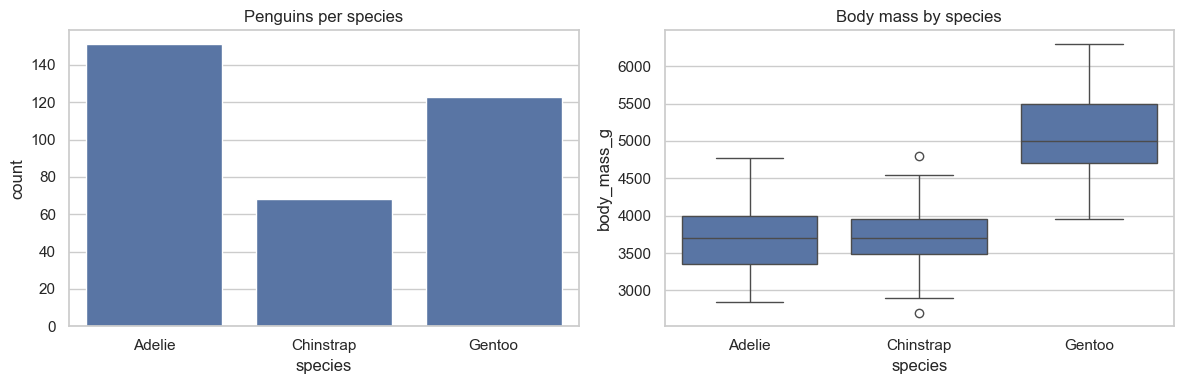

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="species", ax=axes[0])
axes[0].set_title("Penguins per species")
sns.boxplot(data=df, x="species", y="body_mass_g", ax=axes[1])
axes[1].set_title("Body mass by species")
plt.tight_layout()
plt.show()

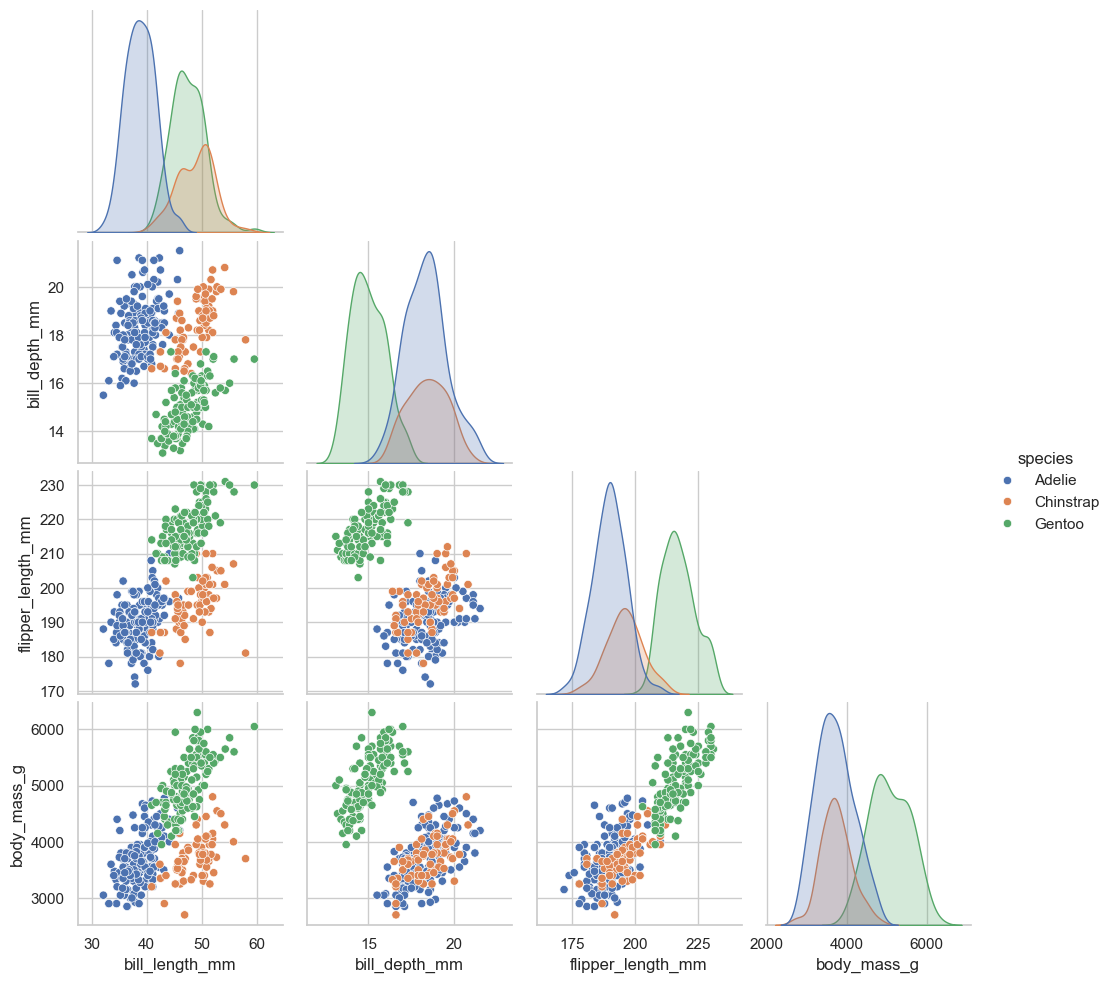

In [79]:
sns.pairplot(df, vars=num_cols, hue="species", corner=True)
plt.show()

In [80]:
display(df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False).to_frame("mean body mass (g)"))
display(df.groupby(["species", "sex"], observed=True)["bill_length_mm"].mean().unstack().round(1))
pd.crosstab(df["island"], df["species"])

,mean body mass (g)
species,
Gentoo,5076.016
Chinstrap,3733.088
Adelie,3700.662


sex,Female,Male
species,,
Adelie,37.3,40.4
Chinstrap,46.6,51.1
Gentoo,45.6,49.5


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,123
Dream,56,68,0
Torgersen,51,0,0


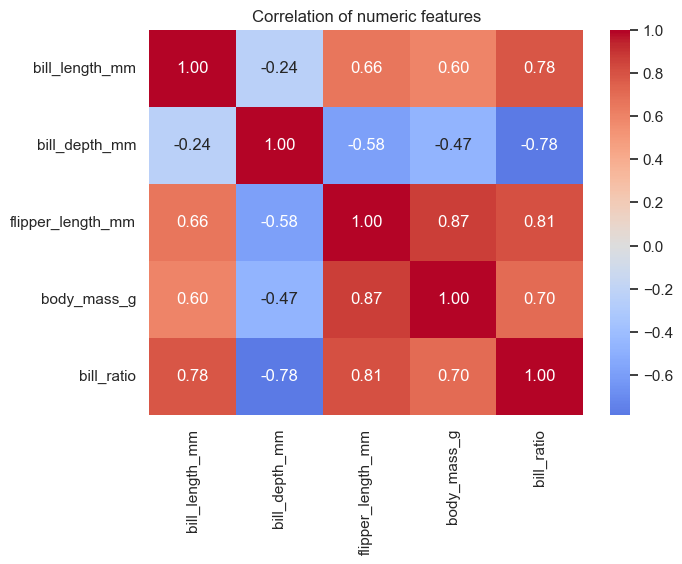

In [81]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["bill_ratio"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation of numeric features")
plt.show()

## 3. Modelling

The preprocessing is part of each model pipeline: numeric features are imputed (median) and scaled, categorical
features (`island`, `sex`) are imputed (most frequent) and one-hot encoded. Because the pipeline is refit inside every
cross-validation fold, no information leaks from validation data.

In [83]:
X = df.drop(columns="species")
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = num_cols + ["bill_ratio"]
categorical_features = ["island", "sex"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", clf)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"model": name,
                 "CV accuracy (mean)": scores.mean(),
                 "CV accuracy (std)": scores.std(),
                 "Test accuracy": accuracy_score(y_test, pipe.predict(X_test))})
results = pd.DataFrame(rows).set_index("model")
results

,CV accuracy (mean),CV accuracy (std),Test accuracy
model,,,
Baseline (majority class),0.442,0.005,0.435
KNN (k=5),0.997,0.006,1.000
Logistic regression,0.997,0.006,1.000
Random forest,0.997,0.006,1.000


## 4. Evaluating the best model

Best model by cross-validation: Logistic regression

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



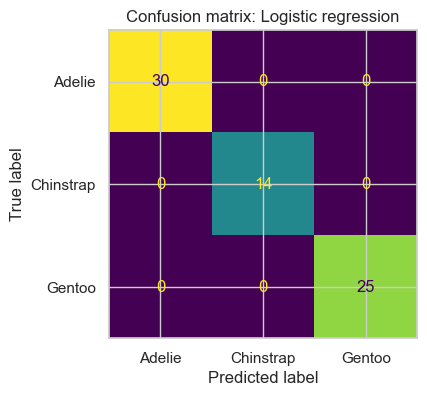

In [85]:
best_name = results.drop(index="Baseline (majority class)")["CV accuracy (mean)"].idxmax()
best_model = fitted[best_name]
best_pred = best_model.predict(X_test)
print("Best model by cross-validation:", best_name)
print()
print(classification_report(y_test, best_pred))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.show()

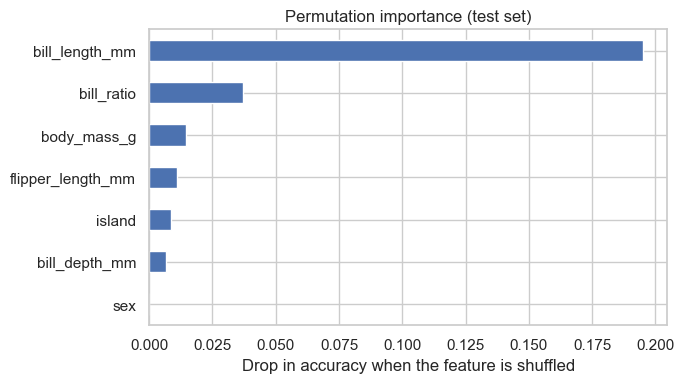

In [86]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=42, scoring="accuracy")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(7, 4))
imp.plot.barh()
plt.xlabel("Drop in accuracy when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()

## 5. Key findings

In [88]:
candidates = results.drop(index="Baseline (majority class)")
top = candidates["CV accuracy (mean)"].max()
tied = candidates.index[candidates["CV accuracy (mean)"] >= top - 0.005].tolist()
base_row = results.loc["Baseline (majority class)"]
best_row = results.loc[best_name]
heaviest = df.groupby("species")["body_mass_g"].mean().idxmax()
top_features = ", ".join(imp.sort_values(ascending=False).head(3).index)

if len(tied) > 1:
    model_line = (f"- **Species are highly separable:** {', '.join(tied)} all reach about {top:.1%} cross-validated "
                  f"accuracy vs {base_row['CV accuracy (mean)']:.1%} for always predicting the most common species. "
                  f"They are effectively tied, so ranking them is not meaningful; {best_name} is shown in the evaluation above.")
else:
    model_line = (f"- **Species are highly separable:** {best_name} reaches {best_row['CV accuracy (mean)']:.1%} "
                  f"cross-validated accuracy (std {best_row['CV accuracy (std)']:.1%}) vs "
                  f"{base_row['CV accuracy (mean)']:.1%} for always predicting the most common species.")

findings = [
    model_line,
    f"- **Test-set caveat:** {best_row['Test accuracy']:.1%} accuracy on the test set comes from only {len(y_test)} penguins, "
    f"so it moves in steps of about {1 / len(y_test):.1%}. The cross-validated figure is the more reliable estimate.",
    f"- **Most informative features:** {top_features} (permutation importance).",
    f"- **Body size:** {heaviest} penguins are the heaviest on average.",
]
display(Markdown("\n".join(findings)))

- **Species are highly separable:** KNN (k=5), Logistic regression, Random forest all reach about 99.7% cross-validated accuracy vs 44.2% for always predicting the most common species. They are effectively tied, so ranking them is not meaningful; Logistic regression is shown in the evaluation above.
- **Test-set caveat:** 100.0% accuracy on the test set comes from only 69 penguins, so it moves in steps of about 1.4%. The cross-validated figure is the more reliable estimate.
- **Most informative features:** bill_length_mm, bill_ratio, body_mass_g (permutation importance).
- **Body size:** Gentoo penguins are the heaviest on average.

## 6. Limitations

- Small and very clean dataset: strong results here do not imply the same accuracy on messy field data.
- `island` is a location proxy. In this data some species live on only one island, which may not hold for new colonies, so a morphology-only model could be more robust.
- Hyperparameters were left at sensible defaults; no extensive tuning was done.